
### About Dataset
Fruits 360 dataset: A dataset of images containing fruits and vegetables

### Content
The following fruits and are included:
Apples (different varieties: Crimson Snow, Golden, Golden-Red, Granny Smith, Pink Lady, Red, Red Delicious), Apricot, Avocado, Avocado ripe, Banana (Yellow, Red, Lady Finger), Beetroot Red, Blueberry, Cactus fruit, Cantaloupe (2 varieties), Carambula, Cauliflower, Cherry (different varieties, Rainier), Cherry Wax (Yellow, Red, Black), Chestnut, Clementine, Cocos, Corn (with husk), Cucumber (ripened), Dates, Eggplant, Fig, Ginger Root, Granadilla, Grape (Blue, Pink, White (different varieties)), Grapefruit (Pink, White), Guava, Hazelnut, Huckleberry, Kiwi, Kaki, Kohlrabi, Kumsquats, Lemon (normal, Meyer), Lime, Lychee, Mandarine, Mango (Green, Red), Mangostan, Maracuja, Melon Piel de Sapo, Mulberry, Nectarine (Regular, Flat), Nut (Forest, Pecan), Onion (Red, White), Orange, Papaya, Passion fruit, Peach (different varieties), Pepino, Pear (different varieties, Abate, Forelle, Kaiser, Monster, Red, Stone, Williams), Pepper (Red, Green, Orange, Yellow), Physalis (normal, with Husk), Pineapple (normal, Mini), Pitahaya Red, Plum (different varieties), Pomegranate, Pomelo Sweetie, Potato (Red, Sweet, White), Quince, Rambutan, Raspberry, Redcurrant, Salak, Strawberry (normal, Wedge), Tamarillo, Tangelo, Tomato (different varieties, Maroon, Cherry Red, Yellow, not ripened, Heart), Walnut, Watermelon.

### Dataset properties
The total number of images: 90380.
The number of classes: 131 (fruits and vegetables).
Image size: 100x100 pixels.

Link to the Dataset: https://www.kaggle.com/datasets/moltean/fruits

### Objective

In this project, we will build a multi-class classification algorithmnn to predict 131 different classes of the fruit 360 dataset using Convolutional Neural Networks (CNN), and fine-tune the CNN Model using Transfer Learning (MobileNet and VGGNet).

### Import Libraries 

In [45]:
# for image processing
import cv2
import numpy as np
import os
import shutil
import random

# for building model
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, Flatten
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

# for visualisation plots
import matplotlib.pyplot as plt
import seaborn as sns


# for transfer learning (MobileNetV2 and VGG16)
from tensorflow.keras.applications import VGG16, MobileNetV2
from tensorflow.keras.applications.vgg16 import preprocess_input 
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input 


### Prepare training, testing and validation images

In [2]:
# Make directory for training, testing and validation images
# Create a function to get images from the image directory to the training, testing and validation directory
# Calculate the number of images for training, testing and validation

def get_images(input_dir):
    train_ratio = 0.7  # 70% of images for training
    test_ratio = 0.2   # 20% of images for testing
    val_ratio = 0.1    # 10% of images for validation

    total_train_images = 0
    total_test_images = 0
    total_val_images = 0

    for category in os.listdir(input_dir):
        category_dir = os.path.join(input_dir, category)
        if os.path.isdir(category_dir):
            # Get a list of image files with the ".jpg" extension in the specified directory
            image_files = [f for f in os.listdir(category_dir) if f.endswith(".jpg")]

            # Shuffle the images 
            random.shuffle(image_files)

            # Calculate the number of images for training, testing, and validation
            num_images = len(image_files)
            num_train = int(num_images * train_ratio)
            num_test = int(num_images * test_ratio)
            num_val = num_images - num_train - num_test

            total_train_images += num_train
            total_test_images += num_test
            total_val_images += num_val

            # Create directory for training, testing and validation
            train_dir = os.path.join(input_dir, "train", category)  
            test_dir = os.path.join(input_dir, "test", category)     
            val_dir = os.path.join(input_dir, "val", category)       

            # Create actual training, testing, and validation folders 
            os.makedirs(train_dir, exist_ok=True)       
            os.makedirs(test_dir, exist_ok=True)        
            os.makedirs(val_dir, exist_ok=True)         

            # Copy the image to the appropriate directory based on the indices
            for i, img_file in enumerate(image_files):
                if i < num_train:
                    shutil.copy(os.path.join(category_dir, img_file), os.path.join(train_dir, img_file))
                elif i < num_train + num_test:
                    shutil.copy(os.path.join(category_dir, img_file), os.path.join(test_dir, img_file))
                else:
                    shutil.copy(os.path.join(category_dir, img_file), os.path.join(val_dir, img_file))
                    

    return total_train_images, total_test_images, total_val_images

# image directory
input_dir = "D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset"  

total_train, total_test, total_val = get_images(input_dir)
print("Total training images:", total_train)
print("Total testing images:", total_test)
print("Total validation images:", total_val)


Total training images: 63220
Total testing images: 18032
Total validation images: 9123


The Fruits 360 dataset was partitioned into training, testing, and validation sets using a distribution ratio of 70% for training, 20% for testing, and 10% for validation.

In [3]:
# Check the size of the images 
# Create a function to check the size of the images 
def checkImageSize(dir, category):
    cat_path = os.path.join(dir, category)
    images = os.listdir(cat_path)
    
    # check sizes of five images 
    for i in range(5):
        img = images[i]
        image = cv2.imread(os.path.join(cat_path, img))
        print(image.shape)

In [4]:
# Obtain the train directory
train_dir = "D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset/train"

# Obtain the test directory
test_dir = "D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset/test"

# Obtain the val directory
val_dir = "D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset/val"

In [5]:
# check size of five images of "Apple Braeburn"
checkImageSize(train_dir, "Apple Braeburn")

(100, 100, 3)
(100, 100, 3)
(100, 100, 3)
(100, 100, 3)
(100, 100, 3)


### Model Building

#### Data Augmentation 

In [6]:
# Define the parameters for data augmentation on the training set
train_datagen = ImageDataGenerator(rescale = 1.0/255, horizontal_flip=True, vertical_flip=True, shear_range=0.2, 
                                   zoom_range=0.2)

# Data augmentation on testing set
test_datagen = ImageDataGenerator(rescale = 1.0/255)  # Normalize the testing set 

# Data augmentation on validation set
val_datagen = ImageDataGenerator(rescale = 1.0/255)    # Normalize the validation set

In [7]:
# Set the image size and batch size 
image_size = (100, 100)
batch_size = 32

# Train the model using the generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical',
    color_mode='rgb'
)


Found 63220 images belonging to 131 classes.
Found 18032 images belonging to 131 classes.
Found 9123 images belonging to 131 classes.


## Model Architecture

#### In this process, we are creating a Convolutional Neural Network (CNN) model with 2 convolutional blocks. Each block consists of a Convolutional layer followed by a MaxPooling layer for feature extraction and dimension reduction. To prevent overfitting, we incorporate a Dropout layer with a dropout rate of 0.5, which randomly drops 50% of the connections during training. The Adam optimizer is chosen for efficient weight updates, and a batch size of 32 is used for training efficiency. The model will be trained for 10 epochs, iterating through the dataset multiple times, to learn and adjust the weights for optimal performance on our task.

In [8]:
# Define model architecture (2 Convolutional Blocks)
model = Sequential()
model.add(Conv2D(32, (3,3), activation = "relu", input_shape = (100, 100, 3), padding = "same"))
model.add(MaxPooling2D((2,2)))
model.add(Conv2D(64, (3,3), activation = "relu"))
model.add(MaxPooling2D((2,2)))
model.add(Flatten())
model.add(Dense(64, activation = "relu"))
model.add(Dropout(0.5))
model.add(Dense(131, activation = "softmax"))

### Model Summary

In [9]:
# Check the summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 100, 100, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 50, 50, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 48, 48, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 24, 24, 64)       0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 36864)             0         
                                                                 
 dense (Dense)               (None, 64)                2

### Define Model Checkpoint and Earlystopping

In [10]:
# Define model checkpoint and early stopping
model_filepath = "D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset"
chkpt = ModelCheckpoint(os.path.join(model_filepath, "cnn_model.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es = EarlyStopping(monitor = "val_loss", patience = 3, verbose = 1)

### Model Compilation

In [11]:
# Compile the model
model.compile(loss='categorical_crossentropy', optimizer="adam", metrics=['accuracy'])

In [12]:
# Train the CNN model
history = model.fit(
   train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=10,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    callbacks = [chkpt, es]
)

Epoch 1/10
1975/1975 [==============================] - ETA: 0s - loss: 2.8045 - accuracy: 0.2362
Epoch 1: val_loss improved from inf to 0.98331, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\cnn_model.hdf5
1975/1975 [==============================] - 334s 165ms/step - loss: 2.8045 - accuracy: 0.2362 - val_loss: 0.9833 - val_accuracy: 0.7638
Epoch 2/10
1975/1975 [==============================] - ETA: 0s - loss: 1.8235 - accuracy: 0.4233
Epoch 2: val_loss improved from 0.98331 to 0.59259, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\cnn_model.hdf5
1975/1975 [==============================] - 85s 43ms/step - loss: 1.8235 - accuracy: 0.4233 - val_loss: 0.5926 - val_accuracy: 0.8625
Epoch 3/10
1975/1975 [==============================] - ETA: 0s - loss: 1.5619 - accuracy: 0.4939
Epoch 3: val_loss improved from 0.59259 to 0.38689, saving model to D:/Applied Aritificial Intelligence__002_CWRKP

### Visualize the Model's Accuracy and Loss

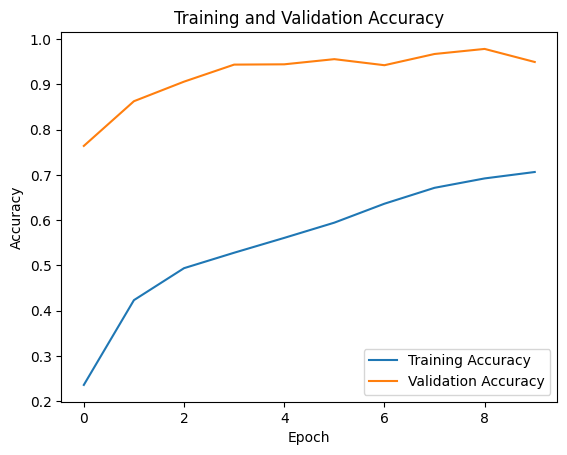

In [13]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

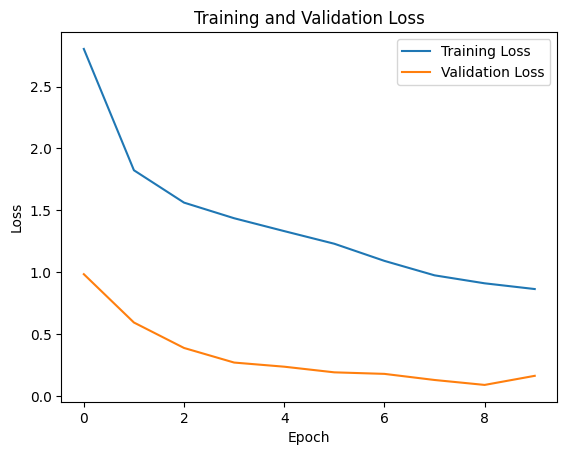

In [14]:
# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [15]:
test_loss, test_acc = model.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 92s 163ms/step - loss: 0.1598 - accuracy: 0.9535
Test loss: 0.15982261300086975
Test accuracy: 0.9535412788391113


## Enhancing the model's performance by adding more layers 

### In this phase, we engage in hyperparameter tuning to enhance the performance of our CNN model. We will achieve this by expanding the architecture to encompass three convolutional blocks, effectively deepening the network. We employ the Adam optimizer to facilitate efficient optimization during training, while maintaining a batch size of 32 for each iteration. To allow the model to learn effectively, we will train it over 10 epochs, a careful choice that balances the trade-off between training time and convergence.

In [16]:
# Define the new model architecture (3 Convolutional Blocks)
model2 = Sequential()
model2.add(Conv2D(32, (3,3), activation = "relu", input_shape = (100, 100, 3), padding = "same"))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(64, (3,3), activation = "relu"))
model2.add(MaxPooling2D((2,2)))
model2.add(Conv2D(128, (3,3), activation = "relu"))
model2.add(MaxPooling2D((2,2)))
model2.add(Flatten())
model2.add(Dense(128, activation = "relu"))
model2.add(Dropout(0.5))
model2.add(Dense(131, activation = "softmax"))

### Model Summary

In [17]:
# Check the summary
model2.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_2 (Conv2D)           (None, 100, 100, 32)      896       
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 50, 50, 32)       0         
 2D)                                                             
                                                                 
 conv2d_3 (Conv2D)           (None, 48, 48, 64)        18496     
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 24, 24, 64)       0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 22, 22, 128)       73856     
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 11, 11, 128)     

### Define Model Checkpoint and Earlystopping

In [18]:
# Define model checkpoint and early stopping
chkpt2 = ModelCheckpoint(os.path.join(model_filepath, "cnn_model2.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es2 = EarlyStopping(monitor = "val_loss", patience = 3, verbose = 1)

### Model Compilation

In [19]:
# Compile the model
model2.compile(loss='categorical_crossentropy', optimizer="adam", metrics=['accuracy'])

In [20]:
# Train the CNN model
history2 = model2.fit(
   train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=10,
    validation_data=val_generator,
    validation_steps=val_generator.samples // batch_size,
    callbacks = [chkpt2, es2]
)

Epoch 1/10
1975/1975 [==============================] - ETA: 0s - loss: 2.0198 - accuracy: 0.4322
Epoch 1: val_loss improved from inf to 0.33116, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\cnn_model2.hdf5
1975/1975 [==============================] - 278s 141ms/step - loss: 2.0198 - accuracy: 0.4322 - val_loss: 0.3312 - val_accuracy: 0.9015
Epoch 2/10
1974/1975 [============================>.] - ETA: 0s - loss: 0.8487 - accuracy: 0.7152
Epoch 2: val_loss improved from 0.33116 to 0.14866, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\cnn_model2.hdf5
1975/1975 [==============================] - 85s 43ms/step - loss: 0.8487 - accuracy: 0.7152 - val_loss: 0.1487 - val_accuracy: 0.9564
Epoch 3/10
1975/1975 [==============================] - ETA: 0s - loss: 0.6201 - accuracy: 0.7878
Epoch 3: val_loss improved from 0.14866 to 0.07299, saving model to D:/Applied Aritificial Intelligence__002_CWR

### Visualize the Model's Accuracy and Loss

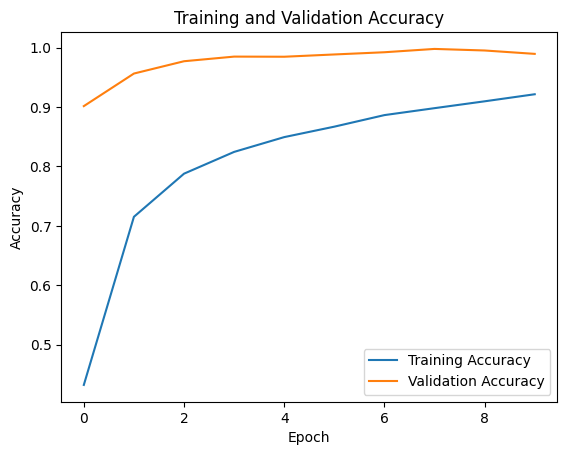

In [21]:
# Plot training and validation accuracy
plt.plot(history2.history['accuracy'], label='Training Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

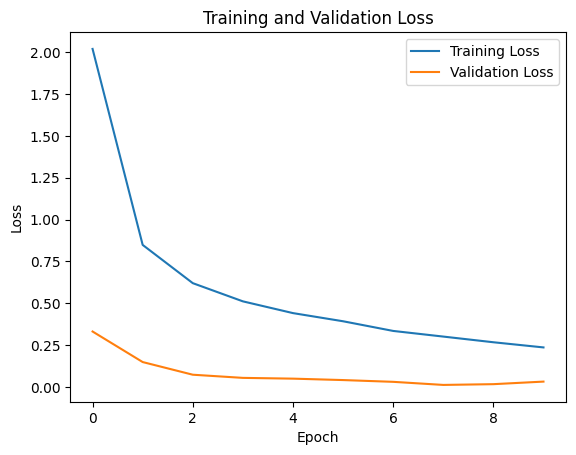

In [22]:
# Plot training and validation loss
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [35]:
test_loss, test_acc = model2.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 106s 187ms/step - loss: 0.0216 - accuracy: 0.9958
Test loss: 0.02162439376115799
Test accuracy: 0.9958370327949524


## Transfer Learning 

In our approach, we harness the power of pretrained models like MobileNetV2 and VGG16 to construct our custom CNN architecture from the ground up. This strategic choice grants us a valuable advantage: the ability to leverage the pretrained weights of these models, which have been meticulously trained on an extensive dataset of millions of images from the ImageNet dataset. By incorporating these pretrained weights, our network gains a head start in recognizing and understanding a wide array of features, enabling it to potentially achieve higher performance and efficiency in various image-based tasks.

## Implementing transfer learning  

## Building and training a VGG16 model with dense layer 1024 neurons, 10 epochs, batch = 32, dropout = 0.5, optimizer = Adam, and activation function = ReLU. 

In [29]:
# Create an ImageDataGenerator for training data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image before training
train_datagen2 = ImageDataGenerator(preprocessing_function = preprocess_input)

# Create an ImageDataGenerator for validation data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image during validation
val_datagen2 = ImageDataGenerator(preprocessing_function = preprocess_input)

In [30]:
# Define the batch size for the data generators
batch_size = 32

# Create a generator for training data from the training directory
# Images will be resized to the target size of (100, 100) and grouped into batches
train_generator2 = train_datagen2.flow_from_directory(train_dir, target_size=(100, 100), batch_size=batch_size)

# Create a generator for validation data from the validation directory
# Images will be resized to the target size of (100, 100) and grouped into batches
val_generator2 = val_datagen2.flow_from_directory(val_dir, target_size=(100, 100), batch_size=batch_size)

Found 63220 images belonging to 131 classes.
Found 9123 images belonging to 131 classes.


In [32]:
### The VGG16 Architecture 

vgg16_model = VGG16(include_top = False, input_shape = (100, 100, 3), weights = "imagenet")

# freeze the layers
for layer in vgg16_model.layers:
    layer.trainable = False
    

# Define the architecture
model3 = Sequential()
model3.add(vgg16_model)
model3.add(Flatten())
model3.add(Dense(1024, activation = "relu"))
model3.add(Dropout(0.5))
model3.add(Dense(131, activation = "softmax"))

In [33]:
# model summary
model3.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 3, 3, 512)         14714688  
                                                                 
 flatten_2 (Flatten)         (None, 4608)              0         
                                                                 
 dense_4 (Dense)             (None, 1024)              4719616   
                                                                 
 dropout_2 (Dropout)         (None, 1024)              0         
                                                                 
 dense_5 (Dense)             (None, 131)               134275    
                                                                 
Total params: 19,568,579
Trainable params: 4,853,891
Non-trainable params: 14,714,688
_________________________________________________________________


In [34]:
# model compilation
model3.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

In [35]:
chkpt3 = ModelCheckpoint(os.path.join(model_filepath, "vgg16_model.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es3 = EarlyStopping(patience = 3, verbose = 1)

In [36]:
# Train the model
history3 = model3.fit(train_generator2, validation_data = val_generator2, epochs = 10, callbacks = [es3, chkpt3])

Epoch 1/10
1976/1976 [==============================] - ETA: 0s - loss: 0.4520 - accuracy: 0.8894
Epoch 1: val_loss improved from inf to 0.01893, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model.hdf5
1976/1976 [==============================] - 315s 159ms/step - loss: 0.4520 - accuracy: 0.8894 - val_loss: 0.0189 - val_accuracy: 0.9973
Epoch 2/10
1975/1976 [============================>.] - ETA: 0s - loss: 0.0825 - accuracy: 0.9739
Epoch 2: val_loss improved from 0.01893 to 0.00703, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model.hdf5
1976/1976 [==============================] - 43s 22ms/step - loss: 0.0825 - accuracy: 0.9738 - val_loss: 0.0070 - val_accuracy: 0.9977
Epoch 3/10
1975/1976 [============================>.] - ETA: 0s - loss: 0.0697 - accuracy: 0.9775
Epoch 3: val_loss improved from 0.00703 to 0.00551, saving model to D:/Applied Aritificial Intelligence__002_C

### Visualize the Model's Accuracy and Loss

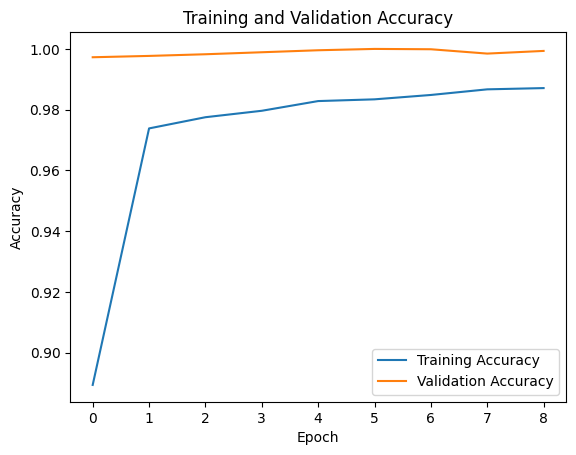

In [37]:
# Plot training and validation accuracy
plt.plot(history3.history['accuracy'], label='Training Accuracy')
plt.plot(history3.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

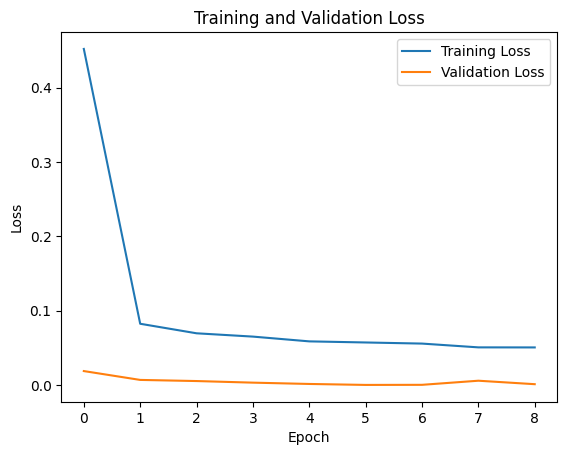

In [38]:
# Plot training and validation loss
plt.plot(history3.history['loss'], label='Training Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [39]:
test_loss, test_acc = model3.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 62s 111ms/step - loss: 8.2599 - accuracy: 0.5032
Test loss: 8.259855270385742
Test accuracy: 0.5032193660736084


## Enhancing the VGG16 model with learning rate = 0.001 and neurons = 512, dropout = 0.5, optimizer = Adam, batch = 32, epochs = 10

In [43]:
### The new VGG16 Architecture 

vgg16_model2 = VGG16(include_top = False, input_shape = (100, 100, 3), weights = "imagenet")

# freeze the layers
for layer in vgg16_model2.layers:
    layer.trainable = False
    

# Define the architecture
model4 = Sequential()
model4.add(vgg16_model2)
model4.add(Flatten())
model4.add(Dense(512, activation = "relu"))
model4.add(Dropout(0.5))
model4.add(Dense(131, activation = "softmax"))

In [44]:
# model summary
model4.summary()

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 3, 3, 512)         14714688  
                                                                 
 flatten_4 (Flatten)         (None, 4608)              0         
                                                                 
 dense_8 (Dense)             (None, 512)               2359808   
                                                                 
 dropout_4 (Dropout)         (None, 512)               0         
                                                                 
 dense_9 (Dense)             (None, 131)               67203     
                                                                 
Total params: 17,141,699
Trainable params: 2,427,011
Non-trainable params: 14,714,688
_________________________________________________________________


In [46]:
# model compilation
optimizer = Adam(learning_rate = 0.001)

model4.compile(optimizer = optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])

In [47]:
chkpt4 = ModelCheckpoint(os.path.join(model_filepath, "vgg16_model2.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es4 = EarlyStopping(patience = 3, verbose = 1)

In [48]:
# Train the model
history4 = model4.fit(train_generator2, validation_data = val_generator2, epochs = 10, callbacks = [es4, chkpt4])

Epoch 1/10
1976/1976 [==============================] - ETA: 0s - loss: 0.5807 - accuracy: 0.8583
Epoch 1: val_loss improved from inf to 0.01173, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model2.hdf5
1976/1976 [==============================] - 244s 123ms/step - loss: 0.5807 - accuracy: 0.8583 - val_loss: 0.0117 - val_accuracy: 0.9993
Epoch 2/10
1975/1976 [============================>.] - ETA: 0s - loss: 0.0789 - accuracy: 0.9769
Epoch 2: val_loss improved from 0.01173 to 0.00522, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model2.hdf5
1976/1976 [==============================] - 42s 21ms/step - loss: 0.0788 - accuracy: 0.9769 - val_loss: 0.0052 - val_accuracy: 0.9992
Epoch 3/10
1975/1976 [============================>.] - ETA: 0s - loss: 0.0721 - accuracy: 0.9763
Epoch 3: val_loss improved from 0.00522 to 0.00178, saving model to D:/Applied Aritificial Intelligence__002

### Visualize the Model's Accuracy and Loss

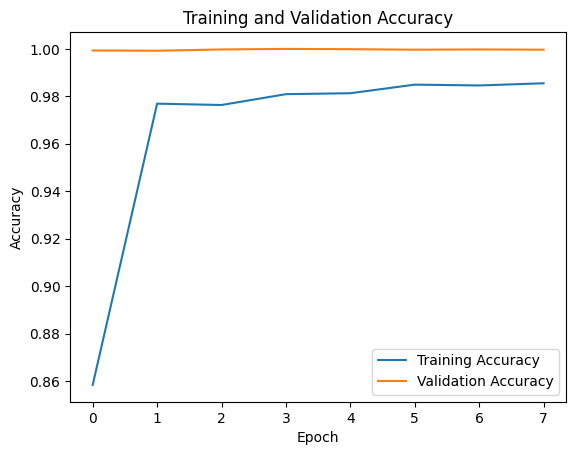

In [49]:
# Plot training and validation accuracy
plt.plot(history4.history['accuracy'], label='Training Accuracy')
plt.plot(history4.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

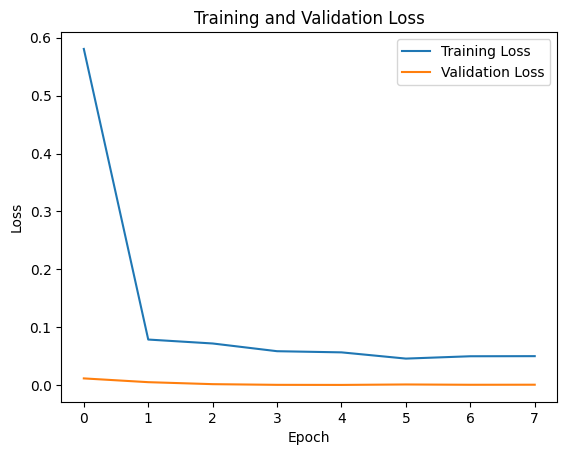

In [59]:
# Plot training and validation loss
plt.plot(history4.history['loss'], label='Training Loss')
plt.plot(history4.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [51]:
test_loss, test_acc = model4.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 67s 118ms/step - loss: 6.1794 - accuracy: 0.5357
Test loss: 6.179361820220947
Test accuracy: 0.5356904864311218


## Enhancing the VGG16 model with learning rate = 0.001, neurons = 256, dropout = 0.5, and epochs = 5

In [52]:
### The new VGG16 Architecture 

vgg16_model3 = VGG16(include_top = False, input_shape = (100, 100, 3), weights = "imagenet")

# freeze the layers
for layer in vgg16_model3.layers:
    layer.trainable = False
    

# Define the architecture
model5 = Sequential()
model5.add(vgg16_model3)
model5.add(Flatten())
model5.add(Dense(256, activation = "relu"))
model5.add(Dropout(0.5))
model5.add(Dense(131, activation = "softmax"))

In [53]:
# model summary
model5.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 3, 3, 512)         14714688  
                                                                 
 flatten_5 (Flatten)         (None, 4608)              0         
                                                                 
 dense_10 (Dense)            (None, 256)               1179904   
                                                                 
 dropout_5 (Dropout)         (None, 256)               0         
                                                                 
 dense_11 (Dense)            (None, 131)               33667     
                                                                 
Total params: 15,928,259
Trainable params: 1,213,571
Non-trainable params: 14,714,688
_________________________________________________________________


In [54]:
# model compilation
optimizer = Adam(learning_rate = 0.001)

model5.compile(optimizer = optimizer, loss = "categorical_crossentropy", metrics = ["accuracy"])

In [55]:
chkpt5 = ModelCheckpoint(os.path.join(model_filepath, "vgg16_model3.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es5 = EarlyStopping(patience = 3, verbose = 1)

In [57]:
# Train the model
history5 = model5.fit(train_generator2, validation_data = val_generator2, epochs = 5, callbacks = [es5, chkpt5])

Epoch 1/5
1975/1976 [============================>.] - ETA: 0s - loss: 0.0664 - accuracy: 0.9774
Epoch 1: val_loss improved from inf to 0.00056, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model3.hdf5
1976/1976 [==============================] - 42s 21ms/step - loss: 0.0664 - accuracy: 0.9774 - val_loss: 5.6118e-04 - val_accuracy: 1.0000
Epoch 2/5
1974/1976 [============================>.] - ETA: 0s - loss: 0.0643 - accuracy: 0.9782
Epoch 2: val_loss did not improve from 0.00056
1976/1976 [==============================] - 42s 21ms/step - loss: 0.0643 - accuracy: 0.9782 - val_loss: 7.4232e-04 - val_accuracy: 0.9999
Epoch 3/5
1976/1976 [==============================] - ETA: 0s - loss: 0.0589 - accuracy: 0.9804
Epoch 3: val_loss improved from 0.00056 to 0.00038, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\vgg16_model3.hdf5
1976/1976 [==============================] - 42s 21ms/step

### Visualize the Model's Accuracy and Loss

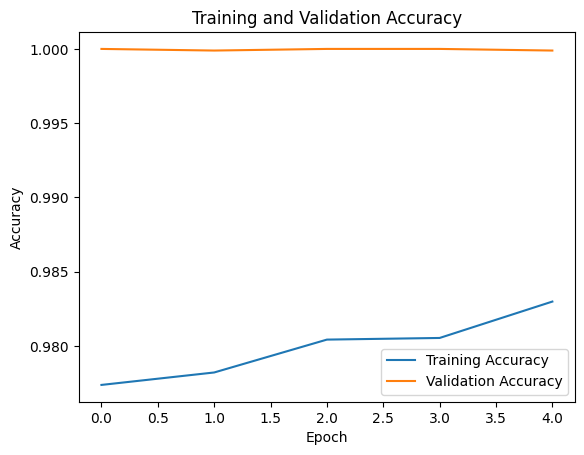

In [58]:
# Plot training and validation accuracy
plt.plot(history5.history['accuracy'], label='Training Accuracy')
plt.plot(history5.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

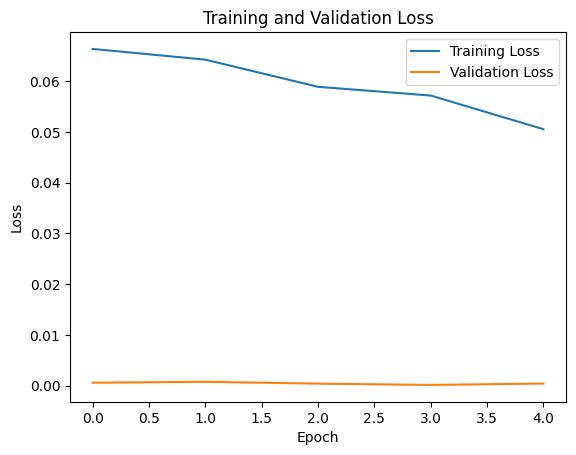

In [60]:
# Plot training and validation loss
plt.plot(history5.history['loss'], label='Training Loss')
plt.plot(history5.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

In [61]:
test_loss, test_acc = model5.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 158s 280ms/step - loss: 6.7625 - accuracy: 0.4742
Test loss: 6.762537956237793
Test accuracy: 0.4741896092891693


## Building and training a MobileNetV2 model with 10 epochs, optimizer 'adam', dense layer of 1024 neurons, batch size of 32, dropout of 0.5, and activation function 'ReLU'

In [77]:
# Create an ImageDataGenerator for training data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image before training
train_datagen3 = ImageDataGenerator(preprocessing_function = preprocess_input)

# Create an ImageDataGenerator for validation data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image during validation
val_datagen3 = ImageDataGenerator(preprocessing_function = preprocess_input)

In [78]:
# Define the batch size for the data generators
batch_size = 32

# Create a generator for training data from the training directory
# Images will be resized to the target size of (100, 100) and grouped into batches
train_generator3 = train_datagen3.flow_from_directory(train_dir, target_size=(100, 100), batch_size=batch_size)

# Create a generator for validation data from the validation directory
# Images will be resized to the target size of (100, 100) and grouped into batches
val_generator3 = val_datagen3.flow_from_directory(val_dir, target_size=(100, 100), batch_size=batch_size)

Found 63220 images belonging to 131 classes.
Found 9123 images belonging to 131 classes.


In [89]:
### The MobileNetV2 Architecture 

mobilenetv2_model = MobileNetV2(include_top = False, input_shape = (100, 100, 3), weights = "imagenet")

# freeze the layers
for layer in mobilenetv2_model.layers:
    layer.trainable = False
    

# Define the architecture
model6 = Sequential()
model6.add(mobilenetv2_model)
model6.add(Flatten())
model6.add(Dense(1024, activation = "relu"))
model6.add(Dropout(0.5))
model6.add(Dense(131, activation = "softmax"))

In [90]:
# model summary
model6.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Funct  (None, 4, 4, 1280)       2257984   
 ional)                                                          
                                                                 
 flatten_12 (Flatten)        (None, 20480)             0         
                                                                 
 dense_24 (Dense)            (None, 1024)              20972544  
                                                                 
 dropout_12 (Dropout)        (None, 1024)              0         
                                                                 
 dense_25 (Dense)            (None, 131)               134275    
                                                                 
Total params: 23,364,803
Trainable params: 21,106,819
Non-trainable params: 2,257,984
_________________________________

In [91]:
# model compilation
model6.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

In [92]:
chkpt6 = ModelCheckpoint(os.path.join(model_filepath, "mobilenetv2_model.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es6 = EarlyStopping(patience = 3, verbose = 1)

In [93]:
# Train the model
history6 = model6.fit(train_generator3, validation_data = val_generator3, epochs = 10, callbacks = [es6, chkpt6])

Epoch 1/10
1976/1976 [==============================] - ETA: 0s - loss: 0.9636 - accuracy: 0.7885
Epoch 1: val_loss improved from inf to 0.04856, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\mobilenetv2_model.hdf5
1976/1976 [==============================] - 243s 122ms/step - loss: 0.9636 - accuracy: 0.7885 - val_loss: 0.0486 - val_accuracy: 0.9840
Epoch 2/10
1972/1976 [============================>.] - ETA: 0s - loss: 0.5623 - accuracy: 0.8825
Epoch 2: val_loss improved from 0.04856 to 0.02206, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\mobilenetv2_model.hdf5
1976/1976 [==============================] - 50s 25ms/step - loss: 0.5629 - accuracy: 0.8825 - val_loss: 0.0221 - val_accuracy: 0.9931
Epoch 3/10
1973/1976 [============================>.] - ETA: 0s - loss: 0.5121 - accuracy: 0.9093
Epoch 3: val_loss improved from 0.02206 to 0.01361, saving model to D:/Applied Aritificial Intelli

### Visualize the Model's Accuracy and Loss

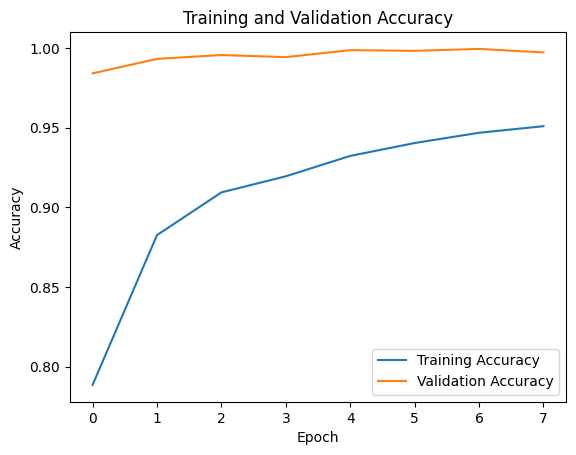

In [94]:
# Plot training and validation accuracy
plt.plot(history6.history['accuracy'], label='Training Accuracy')
plt.plot(history6.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

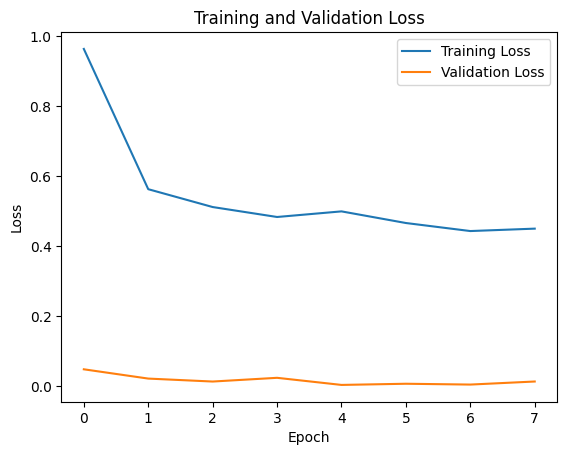

In [95]:
# Plot training and validation loss
plt.plot(history6.history['loss'], label='Training Loss')
plt.plot(history6.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [96]:
test_loss, test_acc = model6.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 58s 103ms/step - loss: 1.9710 - accuracy: 0.8851
Test loss: 1.9710235595703125
Test accuracy: 0.8851021528244019


## Enhance the MobilenetV2 model by increasing the number of epochs, Epochs = 20, dropout = 0.5, optimizer = Adam, number of neurons = 1024

In [97]:
# Create an ImageDataGenerator for training data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image before training
train_datagen4 = ImageDataGenerator(preprocessing_function = preprocess_input)

# Create an ImageDataGenerator for validation data with a preprocessing function
# Preprocessing function preprocess_unit is applied to each image during validation
val_datagen4 = ImageDataGenerator(preprocessing_function = preprocess_input)

In [98]:
# Define the batch size for the data generators
batch_size = 32

# Create a generator for training data from the training directory
# Images will be resized to the target size of (100, 100) and grouped into batches
train_generator4 = train_datagen4.flow_from_directory(train_dir, target_size=(100, 100), batch_size=batch_size)

# Create a generator for validation data from the validation directory
# Images will be resized to the target size of (100, 100) and grouped into batches
val_generator4 = val_datagen4.flow_from_directory(val_dir, target_size=(100, 100), batch_size=batch_size)

Found 63220 images belonging to 131 classes.
Found 9123 images belonging to 131 classes.


In [99]:
### The MobileNetV2 Architecture 

mobilenetv2_model2 = MobileNetV2(include_top = False, input_shape = (100, 100, 3), weights = "imagenet")

# freeze the layers
for layer in mobilenetv2_model2.layers:
    layer.trainable = False
    

# Define the architecture
model7 = Sequential()
model7.add(mobilenetv2_model)
model7.add(Flatten())
model7.add(Dense(1024, activation = "relu"))
model7.add(Dropout(0.5))
model7.add(Dense(131, activation = "softmax"))

In [106]:
# model summary
model7.summary()

Model: "sequential_13"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenetv2_1.00_224 (Funct  (None, 4, 4, 1280)       2257984   
 ional)                                                          
                                                                 
 flatten_13 (Flatten)        (None, 20480)             0         
                                                                 
 dense_26 (Dense)            (None, 1024)              20972544  
                                                                 
 dropout_13 (Dropout)        (None, 1024)              0         
                                                                 
 dense_27 (Dense)            (None, 131)               134275    
                                                                 
Total params: 23,364,803
Trainable params: 21,106,819
Non-trainable params: 2,257,984
_________________________________

In [110]:
# model compilation
model7.compile(optimizer = "adam", loss = "categorical_crossentropy", metrics = ["accuracy"])

In [111]:
chkpt7 = ModelCheckpoint(os.path.join(model_filepath, "mobilenetv2_model.hdf5"), save_best_only=True, verbose = 1)

# Define early stopping
es7 = EarlyStopping(patience = 3, verbose = 1)

In [112]:
# Train the model
history7 = model7.fit(train_generator4, validation_data = val_generator4, epochs = 20, callbacks = [es7, chkpt7])

Epoch 1/20
1976/1976 [==============================] - ETA: 0s - loss: 1.0018 - accuracy: 0.7893
Epoch 1: val_loss improved from inf to 0.03663, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\mobilenetv2_model.hdf5
1976/1976 [==============================] - 37s 18ms/step - loss: 1.0018 - accuracy: 0.7893 - val_loss: 0.0366 - val_accuracy: 0.9876
Epoch 2/20
1973/1976 [============================>.] - ETA: 0s - loss: 0.5722 - accuracy: 0.8841
Epoch 2: val_loss did not improve from 0.03663
1976/1976 [==============================] - 28s 14ms/step - loss: 0.5722 - accuracy: 0.8841 - val_loss: 0.0370 - val_accuracy: 0.9898
Epoch 3/20
1973/1976 [============================>.] - ETA: 0s - loss: 0.5519 - accuracy: 0.9091
Epoch 3: val_loss improved from 0.03663 to 0.01317, saving model to D:/Applied Aritificial Intelligence__002_CWRKProject Report/fruits-360_dataset\mobilenetv2_model.hdf5
1976/1976 [==============================] - 30s 15ms

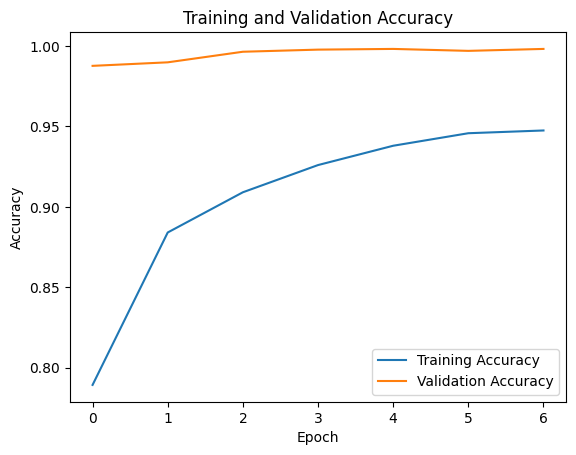

In [113]:
# Plot training and validation accuracy
plt.plot(history7.history['accuracy'], label='Training Accuracy')
plt.plot(history7.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

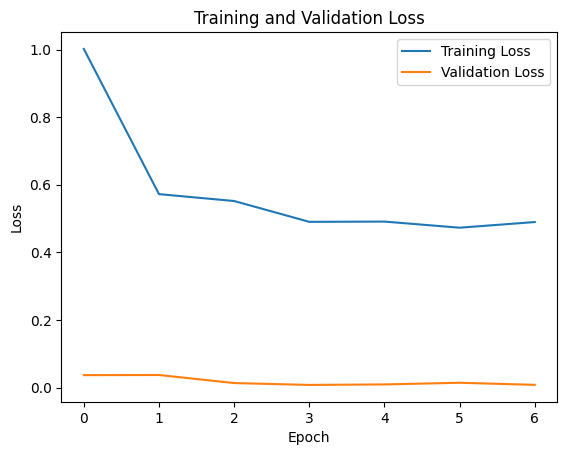

In [114]:
# Plot training and validation loss
plt.plot(history7.history['loss'], label='Training Loss')
plt.plot(history7.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

### Evaluating the model's performance on the test set

In [115]:
test_loss, test_acc = model7.evaluate(test_generator, steps=test_generator.samples // batch_size)
print('Test loss:', test_loss)
print('Test accuracy:', test_acc)

563/563 [==============================] - 7s 12ms/step - loss: 3.0649 - accuracy: 0.8510
Test loss: 3.0649333000183105
Test accuracy: 0.8510212898254395
